<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Shared market hours change when local clocks change

Compare the modeled regular sessions of New York (`XNYS`) and London (`XLON`) across three weeks around their autumn clock changes. Retrieve timezone-aware opening and closing instants, intersect the intervals in SQL, and distinguish a covered closed date from an unknown date outside calendar coverage.

**Calendar definitions, not live market data.** The real worker uses pinned `exchange-calendars 4.13.2`. This example measures modeled overlapping session time; it does not observe trades, account for unexpected halts or extended hours, or establish a settlement deadline. Both chosen markets have continuous regular sessions within these returned bounds; open-to-close spans would need additional break handling for other exchanges.

## Choose one of the three comparison weeks

`WEEK_START` is a Monday session-label date. Choose **`2026-10-19`** (default), **`2026-10-26`** (the experiment), or **`2026-11-02`**. The selected window is seven calendar dates, Monday through Sunday. All three weeks are retrieved for context, so the full-period chart can remain identical across experiments. Restart and run all after editing.

Session labels are dates, while opens/closes are UTC instants. We treat time intervals as **[open, close)**: an event exactly at the close lies outside the session.

In [1]:
WEEK_START = "2026-10-19"

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from notebook_support import finish, theme

assert WEEK_START in {"2026-10-19", "2026-10-26", "2026-11-02"}
theme()
connection = haybarn.connect()
connection.execute("SET TimeZone='UTC'")
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-trading-calendar/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-trading-calendar/notebooks/pyproject.toml.

## Retrieve both pinned calendars once

The literal `uvx` location starts a remotely available Git revision with the tested calendar, pandas, NumPy, timezone-data and VGI versions. No checkout worker or Python calendar computation is used. `trading_schedule` takes **inclusive date endpoints** and returns only sessions; its absence alone cannot tell us whether a date is closed or uncovered. A complete date spine and the per-row `is_trading_day` scalar resolve that distinction.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tcal' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with exchange-calendars==4.13.2 --with pandas==3.1.1 --with numpy==2.5.4 --with tzdata==2026.6 --from git+https://github.com/Query-farm/vgi-trading-calendar@ac3c95091e2b248f995b24767021283cb46a1b9e vgi-trading-calendar-worker');
CREATE TABLE schedules AS
SELECT 'XNYS' AS exchange,* FROM tcal.main.trading_schedule(DATE '2026-10-19',DATE '2026-11-08',exchange:='XNYS')
UNION ALL
SELECT 'XLON' AS exchange,* FROM tcal.main.trading_schedule(DATE '2026-10-19',DATE '2026-11-08',exchange:='XLON');
CREATE TABLE date_spine AS SELECT day::DATE AS day FROM generate_series(DATE '2026-10-19',DATE '2026-11-08',INTERVAL 1 DAY) t(day);
CREATE TABLE availability AS SELECT day,tcal.main.is_trading_day(day,'XNYS') AS ny_session,
 tcal.main.is_trading_day(day,'XLON') AS london_session FROM date_spine;

,Count


## Intersect only covered session intervals

For two open sessions, shared time begins at the later opening and ends at the earlier closing. The positive difference gives overlap minutes; disjoint covered sessions give zero. If either calendar is unknown, overlap remains NULL. A covered closed date gives zero, which means no modeled shared session—not a missing measurement.

All clock-hour columns are extracted explicitly in UTC. The library’s source dates and UTC timestamps remain in the displayed result, rather than replacing them with a timezone-naive local hour.

In [4]:
%%sql
CREATE TABLE daily AS
WITH joined AS (
 SELECT a.*,n.market_open AS ny_open,n.market_close AS ny_close,n.is_early_close AS ny_early,
 l.market_open AS london_open,l.market_close AS london_close,l.is_early_close AS london_early
 FROM availability a LEFT JOIN schedules n ON a.day=n.session AND n.exchange='XNYS'
 LEFT JOIN schedules l ON a.day=l.session AND l.exchange='XLON'
), bounds AS (
 SELECT *,CASE WHEN ny_session AND london_session THEN greatest(ny_open,london_open) END AS shared_open,
 CASE WHEN ny_session AND london_session THEN least(ny_close,london_close) END AS shared_close FROM joined
)
SELECT *,CASE WHEN ny_session IS NULL OR london_session IS NULL THEN 'unknown coverage'
 WHEN NOT ny_session OR NOT london_session THEN 'one or both closed' ELSE 'both open' END AS availability_status,
 CASE WHEN ny_session IS NULL OR london_session IS NULL THEN NULL
 WHEN NOT ny_session OR NOT london_session THEN 0.0
 ELSE greatest(0,date_diff('second',shared_open,shared_close)/60.0) END AS overlap_minutes,
 date_diff('second',ny_open,ny_close)/60.0 AS ny_minutes,
 date_diff('second',london_open,london_close)/60.0 AS london_minutes
FROM bounds;
CREATE TABLE selected_week AS SELECT * FROM daily
WHERE day>=DATE '{{ WEEK_START }}' AND day<DATE '{{ WEEK_START }}'+INTERVAL 7 DAY;

,Count


In [5]:
%%sql week <<
SELECT * FROM selected_week ORDER BY day;

In [6]:
display(week)

,day,ny_session,london_session,ny_open,ny_close,ny_early,london_open,london_close,london_early,shared_open,shared_close,availability_status,overlap_minutes,ny_minutes,london_minutes
0,2026-10-19,True,True,2026-10-19 09:30:00-04:00,2026-10-19 16:00:00-04:00,False,2026-10-19 03:00:00-04:00,2026-10-19 11:30:00-04:00,False,2026-10-19 09:30:00-04:00,2026-10-19 11:30:00-04:00,both open,120.0,390.0,510.0
1,2026-10-20,True,True,2026-10-20 09:30:00-04:00,2026-10-20 16:00:00-04:00,False,2026-10-20 03:00:00-04:00,2026-10-20 11:30:00-04:00,False,2026-10-20 09:30:00-04:00,2026-10-20 11:30:00-04:00,both open,120.0,390.0,510.0
2,2026-10-21,True,True,2026-10-21 09:30:00-04:00,2026-10-21 16:00:00-04:00,False,2026-10-21 03:00:00-04:00,2026-10-21 11:30:00-04:00,False,2026-10-21 09:30:00-04:00,2026-10-21 11:30:00-04:00,both open,120.0,390.0,510.0
3,2026-10-22,True,True,2026-10-22 09:30:00-04:00,2026-10-22 16:00:00-04:00,False,2026-10-22 03:00:00-04:00,2026-10-22 11:30:00-04:00,False,2026-10-22 09:30:00-04:00,2026-10-22 11:30:00-04:00,both open,120.0,390.0,510.0
4,2026-10-23,True,True,2026-10-23 09:30:00-04:00,2026-10-23 16:00:00-04:00,False,2026-10-23 03:00:00-04:00,2026-10-23 11:30:00-04:00,False,2026-10-23 09:30:00-04:00,2026-10-23 11:30:00-04:00,both open,120.0,390.0,510.0
5,2026-10-24,False,False,NaT,NaT,<NA>,NaT,NaT,<NA>,NaT,NaT,one or both closed,0.0,NaN,NaN
6,2026-10-25,False,False,NaT,NaT,<NA>,NaT,NaT,<NA>,NaT,NaT,one or both closed,0.0,NaN,NaN


## See the selected week on a common UTC clock

Each date has a London bar, New York bar and narrower shared interval. The weekday session boundaries—not a fixed timezone-offset assumption—determine the orange interval. Covered closed dates stay in the table above and have no session bars.

In [7]:
%%sql intervals <<
SELECT day,
 date_part('hour',ny_open AT TIME ZONE 'UTC')+date_part('minute',ny_open AT TIME ZONE 'UTC')/60.0 AS ny_start,
 date_part('hour',london_open AT TIME ZONE 'UTC')+date_part('minute',london_open AT TIME ZONE 'UTC')/60.0 AS london_start,
 date_part('hour',shared_open AT TIME ZONE 'UTC')+date_part('minute',shared_open AT TIME ZONE 'UTC')/60.0 AS shared_start,
 ny_minutes/60.0 AS ny_hours,london_minutes/60.0 AS london_hours,overlap_minutes/60.0 AS shared_hours
FROM selected_week WHERE ny_session AND london_session ORDER BY day;

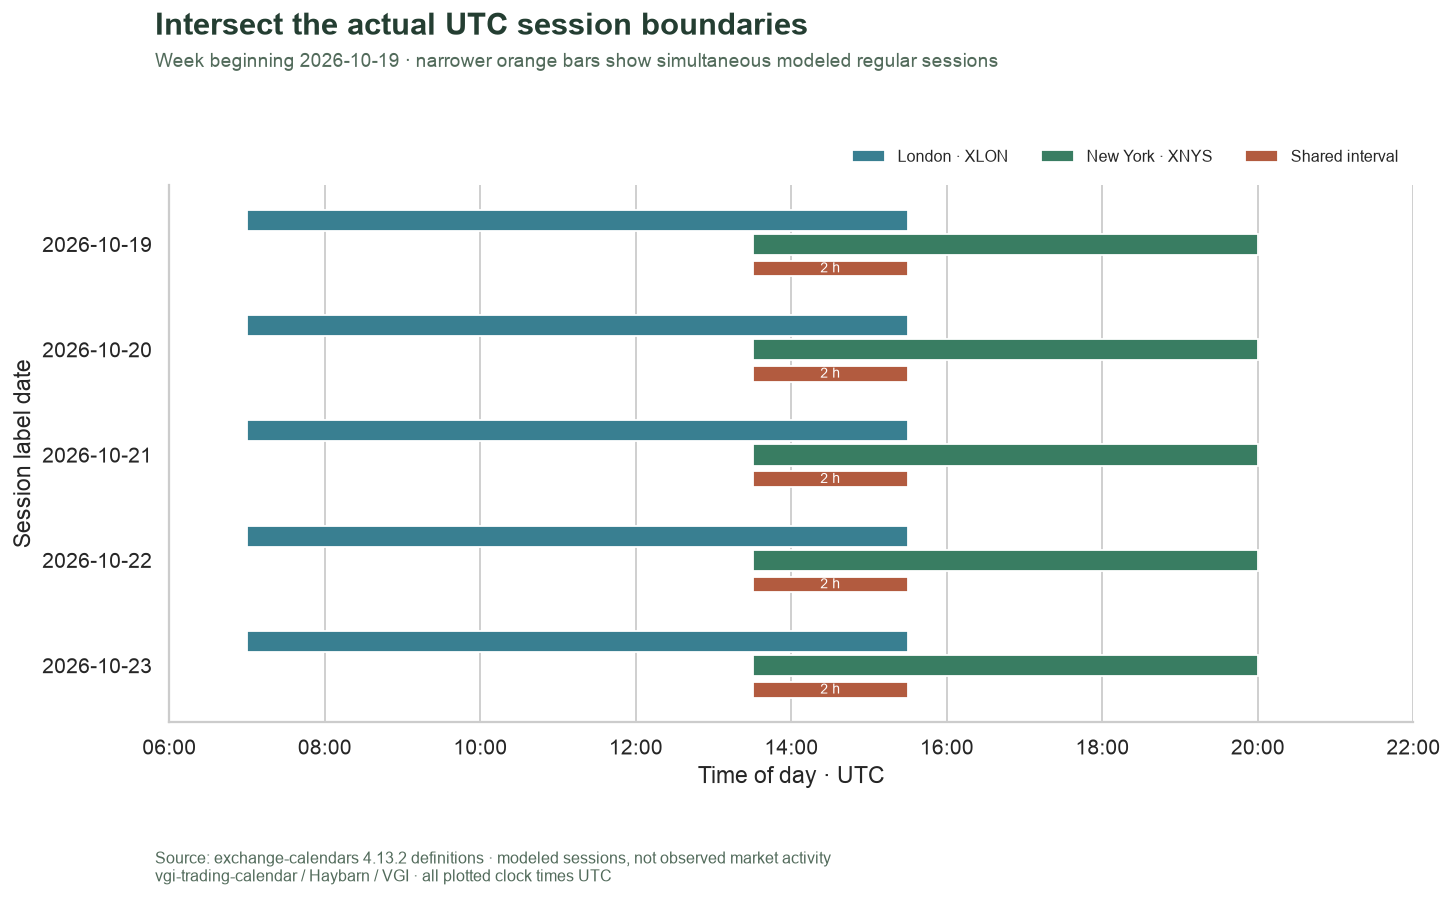

In [8]:
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(intervals))
ax.barh(
    y - 0.23, intervals.london_hours, left=intervals.london_start, height=0.20, color="#397f91", label="London · XLON"
)
ax.barh(y, intervals.ny_hours, left=intervals.ny_start, height=0.20, color="#397d62", label="New York · XNYS")
ax.barh(
    y + 0.23, intervals.shared_hours, left=intervals.shared_start, height=0.15, color="#b25b3f", label="Shared interval"
)
for i, row in enumerate(intervals.itertuples()):
    ax.text(
        row.shared_start + row.shared_hours / 2,
        i + 0.23,
        f"{row.shared_hours:g} h",
        ha="center",
        va="center",
        fontsize=8,
        color="white",
    )
ax.set_yticks(y, [str(d.date()) for d in intervals.day])
ax.set_xticks(range(6, 23, 2), [f"{h:02d}:00" for h in range(6, 23, 2)])
ax.set(xlabel="Time of day · UTC", ylabel="Session label date", xlim=(6, 22))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.01), frameon=False, ncol=3, fontsize=9)
finish(
    fig,
    f"utc-intervals-{WEEK_START}",
    "Intersect the actual UTC session boundaries",
    f"Week beginning {WEEK_START} · narrower orange bars show simultaneous modeled regular sessions",
)

## Compare all three weeks without changing the reference window

The second chart uses the same 21-date relation in every run. Zero markers identify covered closed dates; unknown coverage would be omitted rather than replaced with zero. This context separates a one-week change in shared time from a change in either market’s local regular-session duration.

In [9]:
%%sql period <<
SELECT * FROM daily ORDER BY day;

In [10]:
%%sql weekly <<
SELECT date_trunc('week',day)::DATE AS week_start,count(*) AS calendar_dates,
 count(*) FILTER(WHERE availability_status='both open') AS joint_session_dates,
 count(*) FILTER(WHERE availability_status='unknown coverage') AS unknown_dates,
 sum(overlap_minutes)/60.0 AS shared_hours,
 min(ny_minutes) AS shortest_ny_minutes,max(ny_minutes) AS longest_ny_minutes,
 min(london_minutes) AS shortest_london_minutes,max(london_minutes) AS longest_london_minutes
FROM daily GROUP BY week_start ORDER BY week_start;

,week_start,calendar_dates,joint_session_dates,unknown_dates,shared_hours,shortest_ny_minutes,longest_ny_minutes,shortest_london_minutes,longest_london_minutes
0,2026-10-19,7,5,0,10.0,390.0,390.0,510.0,510.0
1,2026-10-26,7,5,0,15.0,390.0,390.0,510.0,510.0
2,2026-11-02,7,5,0,10.0,390.0,390.0,510.0,510.0


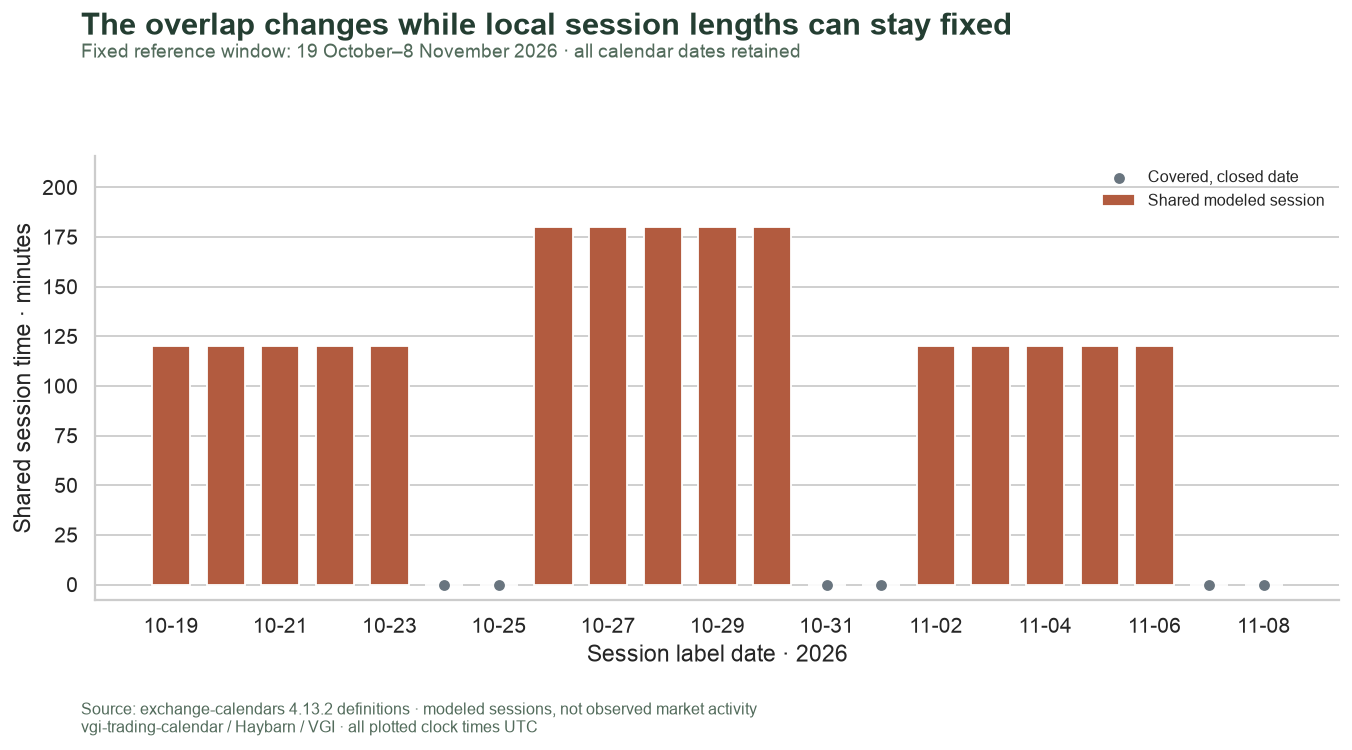

In [11]:
display(weekly)
fig, ax = plt.subplots(figsize=(11, 5.8))
x = np.arange(len(period))
known = period.overlap_minutes.notna()
ax.bar(x[known], period.loc[known, "overlap_minutes"], color="#b25b3f", width=0.7, label="Shared modeled session")
closed = period.availability_status == "one or both closed"
ax.scatter(
    x[closed], np.zeros(int(closed.sum())), marker="o", s=25, color="#69757f", label="Covered, closed date", zorder=4
)
ax.set_xticks(x[::2], [str(d.date())[5:] for d in period.day.iloc[::2]])
ax.set(
    xlabel="Session label date · 2026",
    ylabel="Shared session time · minutes",
    ylim=(-8, max(period.overlap_minutes) * 1.2),
)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
finish(
    fig,
    "three-week-overlap",
    "The overlap changes while local session lengths can stay fixed",
    "Fixed reference window: 19 October–8 November 2026 · all calendar dates retained",
)

In [12]:
chosen = weekly.loc[weekly.week_start.astype(str) == WEEK_START].iloc[0]
ny = intervals.ny_hours.iloc[0]
london = intervals.london_hours.iloc[0]
display(
    Markdown(
        f"The selected week has **{int(chosen.joint_session_dates)} joint session dates** and "
        f"**{chosen.shared_hours:g} shared hours**. Its first joint session spans **{ny:g} hours** in New York "
        f"and **{london:g} hours** in London. Across the reference weeks, total overlap ranges from "
        f"**{weekly.shared_hours.min():g} to {weekly.shared_hours.max():g} hours**. "
        "Use the UTC boundaries and duration columns to distinguish an offset change from a shorter session. "
        "These are versioned calendar definitions; unexpected market events are outside the model."
    )
)

The selected week has **5 joint session dates** and **10 shared hours**. Its first joint session spans **6.5 hours** in New York and **8.5 hours** in London. Across the reference weeks, total overlap ranges from **10 to 15 hours**. Use the UTC boundaries and duration columns to distinguish an offset change from a shorter session. These are versioned calendar definitions; unexpected market events are outside the model.

## Boundary controls: closed, uncovered and exactly at close

The first control contrasts a covered Saturday with an old date outside the library’s default coverage window. Both lack opening times, but `is_trading_day` distinguishes **false** from **NULL**. The worker’s default coverage window moves with execution time, so even a pinned library is not an indefinitely frozen calendar export.

The second control places two invented event instants exactly at the first selected shared open and close. Only the open belongs to **[shared_open, shared_close)**. Session counts use another distinct convention: `trading_days_between` is half-open in **dates**, while `trading_schedule` has inclusive date endpoints.

In [13]:
%%sql controls <<
SELECT day,tcal.main.is_trading_day(day,'XNYS') AS is_session,
 tcal.main.market_open(day,'XNYS') AS market_open,tcal.main.market_close(day,'XNYS') AS market_close
FROM (VALUES (DATE '2026-10-24'),(DATE '1900-01-01')) t(day) ORDER BY day;

In [14]:
%%sql
CREATE TABLE boundary_events AS
WITH first_session AS (SELECT * FROM selected_week WHERE overlap_minutes>0 ORDER BY day LIMIT 1)
SELECT 'at shared open' AS label,shared_open AS event_time,shared_open,shared_close FROM first_session
UNION ALL SELECT 'at shared close',shared_close,shared_open,shared_close FROM first_session;

,Count


In [15]:
%%sql checks <<
SELECT 'daily spine has unique complete dates' AS check_name,
 (SELECT count(*)=21 AND count(*)=count(DISTINCT day) FROM daily) AS passed
UNION ALL SELECT 'selected week retains all seven dates',(SELECT count(*)=7 FROM selected_week)
UNION ALL SELECT 'required reference coverage is known',
 (SELECT bool_and(ny_session IS NOT NULL AND london_session IS NOT NULL) FROM daily)
UNION ALL SELECT 'schedule rows are unique per exchange/date',
 (SELECT count(*)=count(DISTINCT struct_pack(exchange:=exchange,session:=session)) FROM schedules)
UNION ALL SELECT 'session flags match schedule availability',
 (SELECT bool_and(ny_session=(ny_open IS NOT NULL) AND london_session=(london_open IS NOT NULL)) FROM daily)
UNION ALL SELECT 'open sessions have increasing boundaries',
 (SELECT bool_and(market_open<market_close) FROM schedules)
UNION ALL SELECT 'closed dates have zero overlap',
 (SELECT bool_and(overlap_minutes=0) FROM daily WHERE availability_status='one or both closed')
UNION ALL SELECT 'overlap cannot exceed either session',
 (SELECT bool_and(overlap_minutes>=0 AND overlap_minutes<=least(ny_minutes,london_minutes)) FROM daily WHERE ny_session AND london_session)
UNION ALL SELECT 'shared bounds lie within both sessions',
 (SELECT bool_and(shared_open>=ny_open AND shared_open>=london_open AND shared_close<=ny_close AND shared_close<=london_close) FROM daily WHERE overlap_minutes>0)
UNION ALL SELECT 'half-open date count agrees with inclusive schedule query',
 tcal.main.trading_days_between(DATE '2026-10-19',DATE '2026-11-09','XNYS')=(SELECT count(*) FROM schedules WHERE exchange='XNYS')
UNION ALL SELECT 'exact open included and exact close excluded',
 (SELECT bool_and((event_time>=shared_open AND event_time<shared_close)=(label='at shared open')) FROM boundary_events)
UNION ALL SELECT 'weekly sums reconcile to the full period',
 (SELECT abs(sum(hours)-(SELECT sum(overlap_minutes)/60.0 FROM daily))<1e-12 FROM
 (SELECT date_trunc('week',day),sum(overlap_minutes)/60.0 AS hours FROM daily GROUP BY 1));

In [16]:
%%sql boundaries <<
SELECT label,event_time,event_time>=shared_open AND event_time<shared_close AS inside_shared_session
FROM boundary_events ORDER BY event_time;

In [17]:
display(controls)
display(boundaries)
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert pd.isna(controls.iloc[0].is_session)
assert not bool(controls.iloc[1].is_session)
display(Markdown(f"**{len(checks)} SQL checks passed**, plus closed-versus-uncovered control checks."))

,day,is_session,market_open,market_close
0,1900-01-01,<NA>,NaT,NaT
1,2026-10-24,False,NaT,NaT


,label,event_time,inside_shared_session
0,at shared open,2026-10-19 09:30:00-04:00,True
1,at shared close,2026-10-19 11:30:00-04:00,False


,check_name,passed
0,daily spine has unique complete dates,True
1,selected week retains all seven dates,True
2,required reference coverage is known,True
3,schedule rows are unique per exchange/date,True
4,session flags match schedule availability,True
5,open sessions have increasing boundaries,True
6,closed dates have zero overlap,True
7,overlap cannot exceed either session,True
8,shared bounds lie within both sessions,True
9,half-open date count agrees with inclusive sch...,True


**12 SQL checks passed**, plus closed-versus-uncovered control checks.

## Focused experiment: move one week later

Change only **`WEEK_START` from `2026-10-19` to `2026-10-26`**, restart and run all. Predict that London’s UTC bars shift while the New York UTC bars initially stay put, changing shared hours even if each venue’s session length remains unchanged. Compare the selected-week interval plot and weekly totals.

The fixed three-week chart and its source table should remain identical. Optionally inspect `2026-11-02` to see the next modeled offset regime; it is not a second required parameter change. This comparison describes the pinned calendar output, not future venue availability. Restore **`2026-10-19`** for the baseline; the README saves the experiment separately.

In [18]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>